<a href="https://colab.research.google.com/github/SrustiUB/Data-Science/blob/main/Kmeans_%26_HMM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ==========================================================
# PART 1 : DATA COLLECTION
# ==========================================================

!pip install -q yfinance ta hmmlearn

# ----------------------------------------------------------
# Imports
# ----------------------------------------------------------

import yfinance as yf
import pandas as pd
import numpy as np

# ----------------------------------------------------------
# Download NIFTY 50 Data
# ----------------------------------------------------------

ticker = "^NSEI"

df = yf.download(

    ticker,

    start="2015-01-01",

    end="2026-01-01",

    auto_adjust=True,

    progress=False

)

# ----------------------------------------------------------
# Fix MultiIndex (Latest yfinance)
# ----------------------------------------------------------

if isinstance(df.columns, pd.MultiIndex):

    df.columns = df.columns.get_level_values(0)

# ----------------------------------------------------------
# Reset Index
# ----------------------------------------------------------

df.reset_index(inplace=True)

# ----------------------------------------------------------
# Convert to Series
# ----------------------------------------------------------

for col in [

    "Open",

    "High",

    "Low",

    "Close",

    "Volume"

]:

    df[col] = df[col].squeeze()

# ----------------------------------------------------------
# Dataset Information
# ----------------------------------------------------------

print("="*60)

print("NIFTY DATASET")

print("="*60)

print("Shape :", df.shape)

print("\nColumns")

print(df.columns.tolist())

print("\nMissing Values")

print(df.isnull().sum())

print("\nFirst Five Rows")

print(df.head())

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.0/166.0 kB 18.5 MB/s eta 0:00:00
NIFTY DATASET
Shape : (2708, 6)

Columns
['Date', 'Close', 'High', 'Low', 'Open', 'Volume']

Missing Values
Price
Date      0
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

First Five Rows
Price       Date        Close         High          Low         Open  Volume
0     2015-01-02  8395.450195  8410.599609  8288.700195  8288.700195  101900
1     2015-01-05  8378.400391  8445.599609  8363.900391  8407.950195  118200
2     2015-01-06  8127.350098  8327.849609  8111.350098  8325.299805  172800
3     2015-01-07  8102.100098  8151.200195  8065.450195  8118.649902  164100
4     2015-01-08  8234.599609  8243.500000  8167.299805  8191.399902  143800


In [ ]:

# ==========================================================
# PART 2 : FEATURE ENGINEERING
# ==========================================================

import ta

# ----------------------------------------------------------
# Log Returns
# ----------------------------------------------------------

df["Log_Return"] = np.log(
    df["Close"] / df["Close"].shift(1)
)

# ----------------------------------------------------------
# Daily Return
# ----------------------------------------------------------

df["Return"] = df["Close"].pct_change()

# ----------------------------------------------------------
# Rolling Volatility
# ----------------------------------------------------------

df["Volatility"] = (
    df["Return"]
    .rolling(20)
    .std()
)
df["Volume_Change"] = (
    df["Volume"]
    .pct_change()
    .replace([np.inf, -np.inf], 0)
)

df["ROC"] = (
    ta.momentum.ROCIndicator(
        close=df["Close"]
    ).roc()
).replace([np.inf, -np.inf], 0)

# ----------------------------------------------------------
# RSI
# ----------------------------------------------------------

df["RSI"] = ta.momentum.RSIIndicator(
    close=df["Close"],
    window=14
).rsi()

# ----------------------------------------------------------
# MACD
# ----------------------------------------------------------

macd = ta.trend.MACD(df["Close"])

df["MACD"] = macd.macd()

df["MACD_SIGNAL"] = macd.macd_signal()

# ----------------------------------------------------------
# ATR
# ----------------------------------------------------------

atr = ta.volatility.AverageTrueRange(

    high=df["High"],

    low=df["Low"],

    close=df["Close"]

)

df["ATR"] = atr.average_true_range()

# ----------------------------------------------------------
# Bollinger Band Width
# ----------------------------------------------------------

bb = ta.volatility.BollingerBands(
    close=df["Close"],
    window=20
)

df["BB_WIDTH"] = (

    bb.bollinger_hband()

    -

    bb.bollinger_lband()

)

# ----------------------------------------------------------
# ADX
# ----------------------------------------------------------

adx = ta.trend.ADXIndicator(

    high=df["High"],

    low=df["Low"],

    close=df["Close"]

)

df["ADX"] = adx.adx()

# ----------------------------------------------------------
# Rate of Change
# ----------------------------------------------------------

df["ROC"] = ta.momentum.ROCIndicator(
    close=df["Close"]
).roc()

# ----------------------------------------------------------
# Volume Change
# ----------------------------------------------------------

df["Volume_Change"] = (
    df["Volume"].pct_change()
)

# ----------------------------------------------------------
# Momentum
# ----------------------------------------------------------

df["Momentum"] = (
    df["Close"] -
    df["Close"].shift(10)
)

# ----------------------------------------------------------
# Remove Missing Values
# ----------------------------------------------------------

df.dropna(inplace=True)

df.reset_index(drop=True, inplace=True)

# ----------------------------------------------------------
# Selected Features
# ----------------------------------------------------------

features = [

    "Return",

    "Log_Return",

    "Volatility",

    "RSI",

    "MACD",

    "MACD_SIGNAL",

    "ATR",

    "BB_WIDTH",

    "ADX",

    "ROC",

    "Volume_Change",

    "Momentum"

]

X = df[features]

print("="*60)

print("FEATURE ENGINEERING COMPLETED")

print("="*60)

print("Dataset Shape :", X.shape)

print("\nFeatures")

print(X.columns.tolist())

print("\nFirst Five Rows")

print(X.head())

FEATURE ENGINEERING COMPLETED
Dataset Shape : (2606, 12)

Features
['Return', 'Log_Return', 'Volatility', 'RSI', 'MACD', 'MACD_SIGNAL', 'ATR', 'BB_WIDTH', 'ADX', 'ROC', 'Volume_Change', 'Momentum']

First Five Rows
Price    Return  Log_Return  Volatility        RSI       MACD  MACD_SIGNAL  \
0     -0.023354   -0.023631    0.012967  41.857901 -24.156090   -31.386401   
1     -0.012305   -0.012381    0.011697  37.404336 -39.303438   -32.969808   
2     -0.000547   -0.000547    0.011635  37.217090 -51.078117   -36.591470   
3     -0.001962   -0.001964    0.011004  36.511618 -60.993548   -41.471886   
4     -0.008694   -0.008732    0.010407  33.487806 -73.694908   -47.916490   

Price         ATR    BB_WIDTH        ADX       ROC  Volume_Change    Momentum  
0      116.078013  461.584205  31.841487 -0.313463       0.201309 -129.200195  
1      117.968890  449.109442  32.206230 -2.848821       0.167575 -288.149902  
2      116.921098  420.606721  32.723708 -2.809112      -0.097433 -290.35009

In [ ]:
# ==========================================================
# PART 3 : DATA CLEANING + FEATURE SCALING + SEQUENCES
# ==========================================================

import numpy as np

from sklearn.preprocessing import StandardScaler

# ----------------------------------------------------------
# Replace Infinite Values
# ----------------------------------------------------------

X = X.replace([np.inf, -np.inf], np.nan)

# ----------------------------------------------------------
# Remove Missing Values
# ----------------------------------------------------------

X = X.dropna()

# Keep dataframe aligned with X
df = df.loc[X.index].reset_index(drop=True)

X = X.reset_index(drop=True)

# ----------------------------------------------------------
# Standardize Features
# ----------------------------------------------------------

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("="*60)
print("FEATURE SCALING COMPLETED")
print("="*60)

print("Scaled Shape :", X_scaled.shape)

# ----------------------------------------------------------
# Sequence Generation
# ----------------------------------------------------------

sequence_length = 30

X_seq = []

for i in range(sequence_length, len(X_scaled)):

    X_seq.append(
        X_scaled[i-sequence_length:i]
    )

X_seq = np.array(X_seq)

# ----------------------------------------------------------
# Save Dates
# ----------------------------------------------------------

dates = df["Date"].iloc[sequence_length:].reset_index(drop=True)

print("\nSequence Shape :", X_seq.shape)

print("Dates Shape :", dates.shape)

print("Number of Features :", X_seq.shape[2])

FEATURE SCALING COMPLETED
Scaled Shape : (2581, 12)

Sequence Shape : (2551, 30, 12)
Dates Shape : (2551,)
Number of Features : 12


In [ ]:
print(X.isnull().sum())

print("\n")

print(np.isinf(X).sum())

Price
Return           0
Log_Return       0
Volatility       0
RSI              0
MACD             0
MACD_SIGNAL      0
ATR              0
BB_WIDTH         0
ADX              0
ROC              0
Volume_Change    0
Momentum         0
dtype: int64


Price
Return           0
Log_Return       0
Volatility       0
RSI              0
MACD             0
MACD_SIGNAL      0
ATR              0
BB_WIDTH         0
ADX              0
ROC              0
Volume_Change    0
Momentum         0
dtype: int64


In [ ]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# Scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create sequences
sequence_length = 30

X_seq = []

for i in range(sequence_length, len(X_scaled)):
    X_seq.append(X_scaled[i-sequence_length:i])

X_seq = np.array(X_seq)

dates = df["Date"].iloc[sequence_length:].reset_index(drop=True)

print("Scaled Shape :", X_scaled.shape)
print("Sequence Shape :", X_seq.shape)
print("Dates Shape :", dates.shape)
print("Features :", X_seq.shape[2])

Scaled Shape : (2581, 12)
Sequence Shape : (2551, 30, 12)
Dates Shape : (2551,)
Features : 12


In [ ]:
# ==========================================================
# PART 4 : TRANSFORMER AUTOENCODER
# ==========================================================

import tensorflow as tf

from tensorflow.keras.layers import (
    Input,
    Dense,
    MultiHeadAttention,
    LayerNormalization,
    Dropout
)

from tensorflow.keras.models import Model

# ----------------------------------------------------------
# Input
# ----------------------------------------------------------

inputs = Input(
    shape=(X_seq.shape[1], X_seq.shape[2])
)

# ----------------------------------------------------------
# Transformer Encoder
# ----------------------------------------------------------

attention = MultiHeadAttention(

    num_heads=4,

    key_dim=16

)(inputs, inputs)

x = LayerNormalization()(inputs + attention)

# ----------------------------------------------------------
# Feed Forward Network
# ----------------------------------------------------------

ffn = Dense(

    64,

    activation="relu"

)(x)

ffn = Dense(

    X_seq.shape[2]

)(ffn)

x = LayerNormalization()(x + ffn)

# ----------------------------------------------------------
# Latent Representation
# ----------------------------------------------------------

latent = Dense(

    8,

    activation="relu",

    name="latent_space"

)(x)

# ----------------------------------------------------------
# Decoder
# ----------------------------------------------------------

decoder = Dense(

    64,

    activation="relu"

)(latent)

outputs = Dense(

    X_seq.shape[2],

    activation="linear"

)(decoder)

# ----------------------------------------------------------
# Autoencoder
# ----------------------------------------------------------

autoencoder = Model(

    inputs,

    outputs

)

autoencoder.compile(

    optimizer="adam",

    loss="mse"

)

autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 30, 12)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 30, 12)    │      3,276 │ input_layer[0][0… │
│ (MultiHeadAttentio… │                   │            │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 30, 12)    │          0 │ input_layer[0][0… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 30, 12)    │         24 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 30, 64)    │        832 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 30, 12)    │        780 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 30, 12)    │          0 │ layer_normalizat… │
│                     │                   │            │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 30, 12)    │         24 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ latent_space        │ (None, 30, 8)     │        104 │ layer_normalizat… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 30, 64)    │        576 │ latent_space[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 30, 12)    │        780 │ dense_2[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 6,396 (24.98 KB)

 Trainable params: 6,396 (24.98 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ==========================================================
# PART 5 : TRAIN TRANSFORMER AUTOENCODER
# ==========================================================

from tensorflow.keras.callbacks import (

    EarlyStopping,

    ReduceLROnPlateau

)

# ----------------------------------------------------------
# Callbacks
# ----------------------------------------------------------

early_stop = EarlyStopping(

    monitor="val_loss",

    patience=5,

    restore_best_weights=True,

    verbose=1

)

reduce_lr = ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.5,

    patience=3,

    min_lr=1e-6,

    verbose=1

)

# ----------------------------------------------------------
# Train
# ----------------------------------------------------------

history = autoencoder.fit(

    X_seq,

    X_seq,

    epochs=50,

    batch_size=32,

    validation_split=0.20,

    callbacks=[

        early_stop,

        reduce_lr

    ],

    verbose=1

)

print("="*60)

print("TRAINING COMPLETED")

print("="*60)

print("Final Training Loss :", history.history["loss"][-1])

print("Final Validation Loss :", history.history["val_loss"][-1])

Epoch 1/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 12s 90ms/step - loss: 0.8477 - val_loss: 0.5648 - learning_rate: 0.0010
Epoch 2/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.4645 - val_loss: 0.4013 - learning_rate: 0.0010
Epoch 3/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3136 - val_loss: 0.2754 - learning_rate: 0.0010
Epoch 4/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.2252 - val_loss: 0.1934 - learning_rate: 0.0010
Epoch 5/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1831 - val_loss: 0.1721 - learning_rate: 0.0010
Epoch 6/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1641 - val_loss: 0.1555 - learning_rate: 0.0010
Epoch 7/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1513 - val_loss: 0.1499 - learning_rate: 0.0010
Epoch 8/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1374 - val_loss: 0.1363 - learning_rate: 0.0010
Epoch 9/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1224 - val_loss: 0.1327 - learning_rate: 0.0010
Epoch 10/50
64/64 ━━━━━━━━

In [ ]:
# ==========================================================
# PART 6 : EXTRACT LATENT FEATURES
# ==========================================================

from tensorflow.keras.models import Model
import numpy as np

# ----------------------------------------------------------
# Encoder Model
# ----------------------------------------------------------

encoder = Model(

    inputs=autoencoder.input,

    outputs=autoencoder.get_layer("latent_space").output

)

# ----------------------------------------------------------
# Extract Latent Features
# ----------------------------------------------------------

latent_features = encoder.predict(X_seq)

print("="*60)
print("LATENT FEATURES")
print("="*60)

print("Shape :", latent_features.shape)

# ----------------------------------------------------------
# Flatten for Clustering
# ----------------------------------------------------------

latent_flat = latent_features.reshape(

    latent_features.shape[0],

    -1

)

print("\nFlattened Shape :", latent_flat.shape)

print("\nFirst Latent Vector")

print(latent_flat[0])

80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step
LATENT FEATURES
Shape : (2551, 30, 8)

Flattened Shape : (2551, 240)

First Latent Vector
[2.213655   1.2810805  2.6125357  1.9974737  1.8240969  2.549872
 3.2562785  1.218591   2.2785428  1.6958677  2.1549716  1.9809208
 1.8347576  2.7194073  3.2993903  0.9986548  2.1251965  1.9209964
 1.8765877  2.0966253  1.914774   2.722455   3.3786867  0.8255791
 2.1844451  1.9072269  1.8175917  2.031387   1.8946972  2.7872007
 3.3457365  0.8034982  2.3008683  1.7480752  1.8936672  1.8607497
 1.9029558  2.8425975  3.2465777  0.82741153 2.2401786  1.7863159
 1.6464636  1.8258312  1.9280324  2.8702767  3.2086403  0.61552113
 1.871088   1.9231018  1.4198089  2.127798   2.0065935  2.6661868
 3.2571874  0.37037563 2.4387078  1.4524269  2.0896363  1.6968954
 1.8939419  2.841772   3.0523856  0.9237026  2.2357652  1.8654609
 1.5059731  2.0096824  1.9902029  2.7622344  3.1443877  0.60644794
 2.1589487  1.8178364  1.4605678  2.0507855  1.9770675  2.7085934
 3.0804713 

In [ ]:
# ==========================================================
# PART 7 : K-MEANS REGIME DETECTION
# ==========================================================

from sklearn.cluster import KMeans

from sklearn.metrics import (

    silhouette_score,

    davies_bouldin_score,

    calinski_harabasz_score

)

import pandas as pd

# ----------------------------------------------------------
# K-Means
# ----------------------------------------------------------

kmeans = KMeans(

    n_clusters=3,

    random_state=42,

    n_init=10

)

clusters = kmeans.fit_predict(latent_flat)

# ----------------------------------------------------------
# Evaluation
# ----------------------------------------------------------

silhouette = silhouette_score(

    latent_flat,

    clusters

)

dbi = davies_bouldin_score(

    latent_flat,

    clusters

)

ch = calinski_harabasz_score(

    latent_flat,

    clusters

)

# ----------------------------------------------------------
# Save Results
# ----------------------------------------------------------

results = pd.DataFrame({

    "Date": dates,

    "Close": df["Close"].iloc[-len(dates):].values,

    "Regime": clusters

})

print("="*60)

print("K-MEANS RESULTS")

print("="*60)

print("Silhouette Score :", round(silhouette,4))

print("Davies-Bouldin Index :", round(dbi,4))

print("Calinski-Harabasz :", round(ch,2))

print("\nCluster Counts")

print(results["Regime"].value_counts())

print("\nFirst Five Rows")

print(results.head())

K-MEANS RESULTS
Silhouette Score : 0.2299
Davies-Bouldin Index : 1.6456
Calinski-Harabasz : 587.07

Cluster Counts
Regime
2    1332
0     908
1     311
Name: count, dtype: int64

First Five Rows
        Date        Close  Regime
0 2015-07-14  8454.099609       2
1 2015-07-15  8523.799805       2
2 2015-07-16  8608.049805       2
3 2015-07-17  8609.849609       2
4 2015-07-20  8603.450195       2


In [ ]:
# ==========================================================
# PART 9 : HIDDEN MARKOV MODEL
# ==========================================================

from hmmlearn.hmm import GaussianHMM

# ----------------------------------------------------------
# Train HMM
# ----------------------------------------------------------

hmm = GaussianHMM(

    n_components=3,

    covariance_type="diag",

    n_iter=500,

    random_state=42

)

hmm.fit(X_scaled)

# ----------------------------------------------------------
# Predict Hidden States
# ----------------------------------------------------------

hmm_states = hmm.predict(X_scaled)

# Align with sequence dates
hmm_states = hmm_states[sequence_length:]

# ----------------------------------------------------------
# Save Results
# ----------------------------------------------------------

results["HMM_Regime"] = hmm_states

print("="*60)
print("HIDDEN MARKOV MODEL RESULTS")
print("="*60)

print(results.head())

print("\nState Counts")

print(results["HMM_Regime"].value_counts())

HIDDEN MARKOV MODEL RESULTS
        Date        Close  Regime  HMM_Regime
0 2015-07-14  8454.099609       2           2
1 2015-07-15  8523.799805       2           2
2 2015-07-16  8608.049805       2           2
3 2015-07-17  8609.849609       2           2
4 2015-07-20  8603.450195       2           2

State Counts
HMM_Regime
2    1438
0     974
1     139
Name: count, dtype: int64


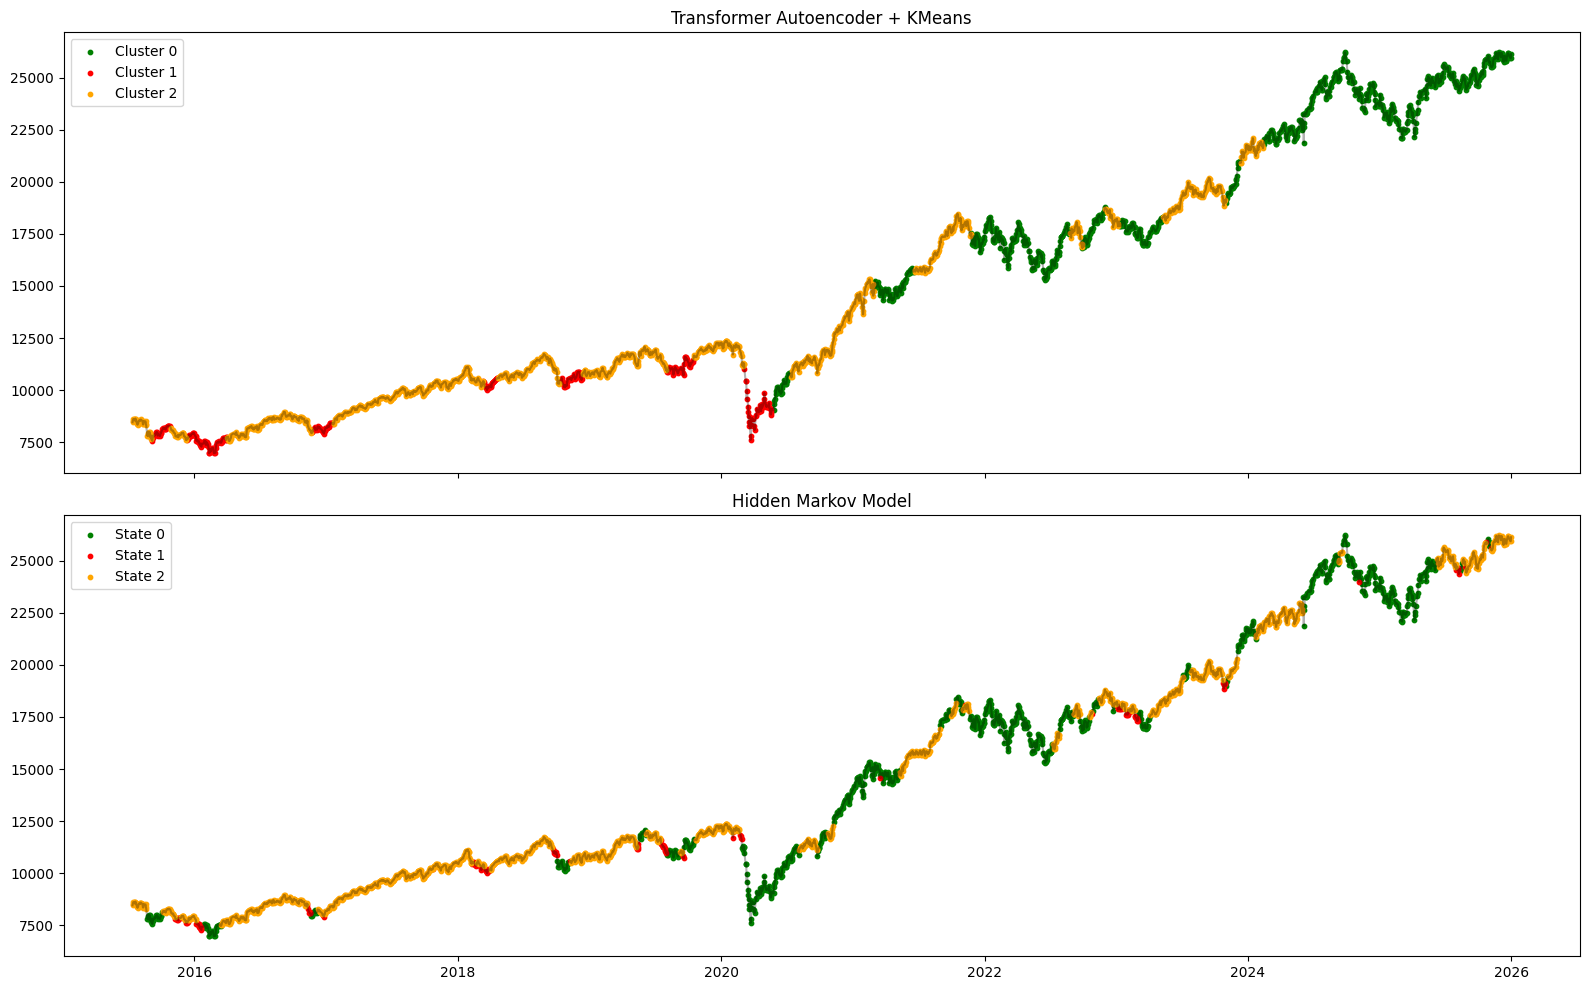

In [ ]:
# ==========================================================
# PART 11 : VISUAL COMPARISON
# ==========================================================

import matplotlib.pyplot as plt

fig, ax = plt.subplots(

    2,

    1,

    figsize=(16,10),

    sharex=True

)

# -----------------------------
# Transformer
# -----------------------------

colors = {

    0:"green",

    1:"red",

    2:"orange"

}

for regime in sorted(results["Regime"].unique()):

    temp = results[

        results["Regime"] == regime

    ]

    ax[0].scatter(

        temp["Date"],

        temp["Close"],

        s=10,

        color=colors[regime],

        label=f"Cluster {regime}"

    )

ax[0].plot(

    results["Date"],

    results["Close"],

    color="black",

    alpha=0.30

)

ax[0].set_title("Transformer Autoencoder + KMeans")

ax[0].legend()

# -----------------------------
# HMM
# -----------------------------

for regime in sorted(results["HMM_Regime"].unique()):

    temp = results[

        results["HMM_Regime"] == regime

    ]

    ax[1].scatter(

        temp["Date"],

        temp["Close"],

        s=10,

        color=colors[regime],

        label=f"State {regime}"

    )

ax[1].plot(

    results["Date"],

    results["Close"],

    color="black",

    alpha=0.30

)

ax[1].set_title("Hidden Markov Model")

ax[1].legend()

plt.tight_layout()

plt.show()

In [ ]:
# ==========================================================
# PART 10 : MODEL COMPARISON
# ==========================================================

from sklearn.metrics import adjusted_rand_score

ari = adjusted_rand_score(

    results["Regime"],

    results["HMM_Regime"]

)

print("="*60)

print("MODEL COMPARISON")

print("="*60)

print(f"K-Means Silhouette Score : {silhouette:.4f}")

print(f"Davies-Bouldin Index : {dbi:.4f}")

print(f"Calinski-Harabasz : {ch:.2f}")

print(f"\nAdjusted Rand Index : {ari:.4f}")

MODEL COMPARISON
K-Means Silhouette Score : 0.2299
Davies-Bouldin Index : 1.6456
Calinski-Harabasz : 587.07

Adjusted Rand Index : 0.1850
